# FPL squad selection and rolling replay

A virtual manager starts before GW1, carries holdings through GW10, and selects a
retrospective GW11 lineup. The preseason-start policy scored **593 points**, compared
with **563** for the sum of the published weekly averages. Initial squad quality explains
much of the difference between policies; ten gameweeks do not establish general superiority.

Three forecast sources and two selection variants share the same dated candidate pools
and rules. The tables and figure use the public summary in `reports/public/squad_results.json`.

[Scoring policy](../docs/fpl_rules.md) · [Collection and preparation](../docs/fpl_collection_learning.md)

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
summary = json.loads((PROJECT_ROOT / "reports/public/squad_results.json").read_text())
assert summary["schema_version"] == "fpl_public_squad_results_v1"
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 12)
POLICY = ["source", "variant"]

## What was replayed

Each decision uses a pre-deadline roster, prices and schedule. Earlier results enter
history after kickoff plus 24 hours. Player history and team context stay fixed across
the four-week forecast horizon. The model is held fixed while eligible histories advance.

Recent-five and frozen XGBoost begin with their original cold-start handling. A third
policy uses a separately validated prior-season points/minutes forecast at the GW1 origin,
then the same frozen XGBoost forecasts from GW2 onward. Unverified preseason histories
receive position fallbacks.

In [2]:
display(pd.DataFrame(summary["protocol"]).set_index("setting"))

,value
setting,
Initial squad,£100m; 15 players; standard FPL composition
Decision horizon,"Four gameweeks, capped at GW19"
Transfers,Hold or at most one free move per deadline
Scoring,"Official points, legal autosubs and captain/vi..."
Availability boundary,Dated captures; results after kickoff + 24h
Policies,Standard; maximum two starting DEF per club
Chips and paid transfers,Unused in this replay


## Selection and continuing ownership

A mixed-integer optimiser jointly chooses the squad, starting XI and captain. For the
forecast horizon, its primary objective is:

$$
\max\sum_{h}\sum_p\widehat P_{p,h}(x_{p,h}+c_{p,h})
$$

Here, $x$ marks starters and $c$ adds the extra captain copy. The constraints enforce
15 players, positional quotas, budget, at most three per club and legal starting formations.
The second variant also allows at most two starting defenders per club.

Purchase prices and bank persist. Later decisions compare holding with one free transfer,
using official selling-price rounding. Fewer transfers, bench forecasts and lower spending
break objective ties in that order. Realised scoring applies ordered legal substitutions
and captain-to-vice fallback.

## GW1–10 results

All six managers used nine free transfers after their opening selection, with no paid
transfers or chips. The reference averages include managers using chips; their aggregate
transfer-hit treatment is unverified. Weekly maximum scores may belong to different managers.
Captain points below are the extra captain copy.

In [3]:
totals = pd.DataFrame(summary["manager_totals"])
display(totals.set_index(POLICY).rename(columns={
    "net_points": "Points", "moves": "Transfers", "captain_points": "Captain extra",
    "auto_sub_points": "Autosub points", "vs_average": "Gap to average",
}))

Points  Transfers  Captain extra  \
source              variant                                          
Recent-five         Defender cap     279          9             35   
                    Standard         299          9             33   
Frozen XGBoost      Defender cap     367          9             39   
                    Standard         307          9             38   
Preseason → XGBoost Defender cap     593          9             43   
                    Standard         593          9             43   

                                  Autosub points  Gap to average  
source              variant                                       
Recent-five         Defender cap               0            -284  
                    Standard                   2            -264  
Frozen XGBoost      Defender cap               3            -196  
                    Standard                   5            -256  
Preseason → XGBoost Defender cap              23              30  
                    Standard                  23              30

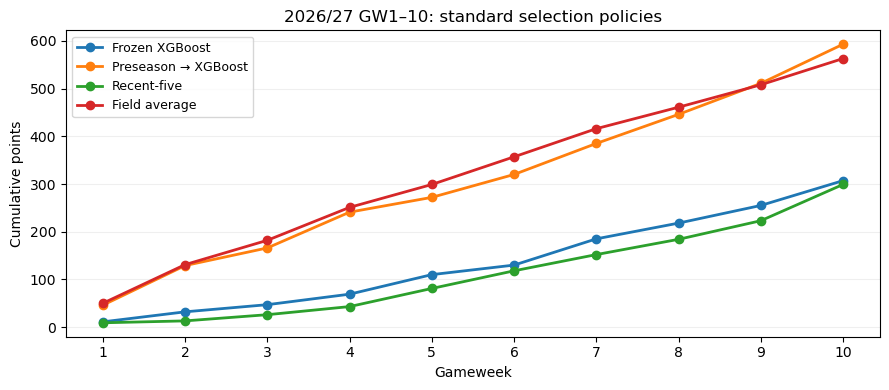

In [4]:
weekly = pd.DataFrame(summary["weekly"])
benchmark = pd.DataFrame(summary["benchmark"]).set_index("GW")
curves = weekly.loc[weekly.variant.eq("Standard")].pivot(
    index="GW", columns="source", values="cumulative_net",
)
curves["Field average"] = benchmark.manager_average.cumsum()
ax = curves.plot(figsize=(9, 4), linewidth=2, marker="o")
ax.set(xlabel="Gameweek", ylabel="Cumulative points", title="2026/27 GW1–10: standard selection policies")
ax.set_xticks(curves.index)
ax.grid(axis="y", alpha=.2)
ax.legend(title=None, fontsize=9)
plt.tight_layout()
plt.show()

## Forecast accuracy and the opening squad

Forecast errors use **6,520 matched player-fixtures**, with three club-change exclusions
shared across sources. The preseason policy changes only GW1-origin forecasts. Its opening
XI contained eleven players who played at least 60 minutes, while the original baselines
selected many non-playing or low-minute players. With one transfer per deadline, those
opening choices continued to affect later results.

In [5]:
display(pd.DataFrame(summary["forecast_accuracy"]).set_index("source").rename(columns={
    "records": "Player-fixtures", "bias": "Forecast minus actual",
}))
display(pd.DataFrame(summary["opening"]).set_index(POLICY).rename(columns={
    "XI_with_minutes": "XI who played", "XI_60_plus": "XI with 60+ minutes",
    "net_points": "GW1 points",
}))

,Player-fixtures,MAE,RMSE,Forecast minus actual
source,,,,
Recent-five,6520,1.2904,2.3795,0.0007
Frozen XGBoost,6520,1.1428,2.0895,-0.0698
Preseason → XGBoost,6520,1.1397,2.0768,-0.0549


XI who played  XI with 60+ minutes  \
source              variant                                            
Recent-five         Defender cap              4                    1   
                    Standard                  3                    2   
Frozen XGBoost      Defender cap              7                    3   
                    Standard                  6                    1   
Preseason → XGBoost Defender cap             11                   11   
                    Standard                 11                   11   

                                  GW1 points  
source              variant                   
Recent-five         Defender cap           7  
                    Standard               9  
Frozen XGBoost      Defender cap          13  
                    Standard              11  
Preseason → XGBoost Defender cap          46  
                    Standard              46

## Saved GW11 recommendation

The standard preseason-start manager uses its continuing holdings and one free transfer.
This is a retrospective recommendation based on the saved pre-deadline information; GW11
outcomes remain excluded. The horizon total assumes those holdings stay fixed through GW14.

In [6]:
gw11 = summary["gw11"]
display(pd.Series({
    "Information captured (UTC)": gw11["as_of_utc"],
    "Transfer": f'{gw11["outgoing"]} → {gw11["incoming"]}',
    "Formation": gw11["formation"], "Captain": gw11["captain"], "Vice": gw11["vice"],
    "Bank (£m)": gw11["bank_m"], "Projected GW11 points": gw11["expected_points"],
    "Projected GW11–14 points": gw11["expected_horizon_points"],
}).to_frame("Recommendation"))

,Recommendation
Information captured (UTC),2026-11-21 06:47:00+00:00
Transfer,Walle Egeli → Evanilson
Formation,3-5-2
Captain,Ødegaard
Vice,Barry
Bank (£m),4.6000
Projected GW11 points,54.8000
Projected GW11–14 points,217.9700


In [7]:
display(pd.DataFrame(gw11["lineup"]).rename(columns={
    "web_name": "Player", "position": "Position", "role": "Role",
    "expected_points": "Projected points",
}).set_index(["Role", "Position"]))

Player  Projected points
Role       Position                             
XI         GK             Raya            4.0064
           DEF         Gabriel            4.1020
           DEF       Van Hecke            4.3328
           DEF       De Cuyper            4.2158
Captain    MID        Ødegaard            5.0598
XI         MID          Rogers            4.4351
           MID       Tavernier            4.7068
           MID            Groß            4.9751
           MID          Mbeumo            3.8966
           FWD       Evanilson            4.9521
Vice       FWD           Barry            5.0550
Reserve GK GK         Dubravka            0.0507
Bench 1    DEF        Truffert            3.2723
Bench 2    DEF           Guéhi            1.9823
Bench 3    FWD          Thiago            0.7154

## Interpretation and limits

The replay evaluates complete decision policies, including different opening squads.
It does not isolate the contribution of XGBoost. A future comparison should give forecast
alternatives the same initial holdings.

The standard lineups already met the defender cap. Different tied selections can lead to
different later holdings, so score differences do not establish a benefit from diversification.

The first ten gameweeks now inform development. Later unseen deadlines are needed for
prospective assessment. Some football statistics were collected later and may contain
corrections; the fixed result delay approximates when information became available.

## Next stage

1. Connect collection, preparation, forecasting and selection through one repeatable command
2. Store football records, dated snapshots and per-user manager state in PostgreSQL
3. Package the application with Docker and schedule updates on a server
4. Add Telegram commands and then explanations grounded in computed results

Appearance and 60-minute forecasts are a separate registered research experiment.
The current replay and forecasts remain the reference version.

## Preparation summary

The retrospective GW1–10 replay and GW11 recommendation are complete. The working
notebook retains the detailed audits; this report reproduces selected results from the
public summary. Database integration, deployment and the Telegram application are planned.